## Iranian Transaction Dataset
- I will be performing various tasks like understanding data, cleaning, filtering, EDA, Model training, etc.
- With the help of this dataset I will be practicing the whole cycle of a Machine Learning Model.


Columns of dataset:
 - status (str) 
 - time (str)         
 - card_type (str)    
 - city (str)         
 - amount (float)   
 - id (int)        

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('./Iranian_Transactions.csv')
df

,status,time,card_type,city,amount,id
0,success,2025-09-07 10:48:00,Visa,Tehran,1427657.0,98
1,success,2025-09-20 13:10:00,MastCard,Tehran,1578078.0,52
2,fail,2025-09-29 03:27:00,Visa,Tehran,250000.0,20
3,success,2025-09-15 13:13:00,Discover,Isfahan,0.0,40
4,success,2025-09-11 11:11:00,Visa,Tehran,1782689.0,59
...,...,...,...,...,...,...
9995,succeed,2025-09-25 14:30:00,MastCard,Karaj,1.0,38
9996,fail,2025-09-28 10:48:00,Vsa,tehr@n,1578078.0,54
9997,success,2025-09-05 21:23:00,Discover,Tabriz,1000.0,67
9998,Success,2025-09-24 10:48:00,MasterCard,Tehran,585954.0,53


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   status     10000 non-null  str    
 1   time       10000 non-null  str    
 2   card_type  9689 non-null   str    
 3   city       9884 non-null   str    
 4   amount     10000 non-null  float64
 5   id         10000 non-null  int64  
dtypes: float64(1), int64(1), str(4)
memory usage: 468.9 KB


In [4]:
df.isnull().sum()

status         0
time           0
card_type    311
city         116
amount         0
id             0
dtype: int64

In [8]:
df['card_type'].value_counts()

card_type
Visa           2358
Discover       1647
MasterCard     1445
Amex           1263
MastCard       1000
Vsa             801
Master-Card     595
visa            206
Master Card     194
VISA            180
Name: count, dtype: int64

In [9]:
df['city'].unique()

<StringArray>
[ 'Tehran', 'Tehran ', 'Isfahan',  'Tabriz',  'Shiraz',  'TEHRAN',   'karaj',
   'Ahvaz',     'THR',     'Qom', 'Mashhad',  'tehr@n',   'Karaj',       nan,
   'ThRan']
Length: 15, dtype: str

In [10]:
df['city'].value_counts()

city
Tehran     2063
Tabriz     1368
Isfahan    1073
Mashhad     900
Shiraz      727
Qom         669
Karaj       642
Ahvaz       632
THR         409
TEHRAN      403
karaj       395
tehr@n      332
Tehran      192
ThRan        79
Name: count, dtype: int64

In [11]:
df[df["card_type"].isnull()].head()

,status,time,card_type,city,amount,id
21,failed,2025-09-21 11:11:00,NaN,karaj,250000.0,52
62,success,2025-09-04 16:40:00,NaN,TEHRAN,-5000.0,72
105,failed,2025-09-15 22:27:00,NaN,Tabriz,585954.0,77
118,success,2025-09-21 13:10:00,NaN,Mashhad,471227.0,45
269,success,2025-09-02 14:30:00,NaN,Ahvaz,452545.0,47


In [12]:
df[df["card_type"].isnull()]["status"].value_counts()

status
success    122
fail       122
failed      37
Success     15
succeed      9
FAIL         6
Name: count, dtype: int64

In [13]:
df[df["card_type"].isnull()]["amount"].describe()

count    3.110000e+02
mean     2.577024e+08
std      1.585566e+09
min     -9.999990e+05
25%      1.234500e+04
50%      4.190890e+05
75%      9.142820e+05
max      1.000000e+10
Name: amount, dtype: float64

In [14]:
df['card_type'] = df['card_type'].fillna('Unknown')
df['city'] = df['city'].fillna('Unknown')

In [ ]:
for r in df['status']:
    if r in ['success','Success','succeed']:
        df['status'] = df['status'].replace(r,'Success')


In [18]:
#better way
df['status'] = df['status'].replace(
    ['fail','failed','FAIL'], 'Failed'
)

In [19]:
df['status'].value_counts()

status
Failed     5366
Success    4634
Name: count, dtype: int64

In [21]:
df.describe()

,amount,id
count,1.000000e+04,10000.000000
mean,2.954735e+08,50.061200
std,1.692035e+09,28.870875
min,-9.999990e+05,1.000000
25%,1.005000e+02,25.000000
50%,3.436790e+05,50.000000
75%,9.144650e+05,74.000000
max,1.000000e+10,100.000000


In [22]:
df.columns

Index(['status', 'time', 'card_type', 'city', 'amount', 'id'], dtype='str')

<Axes: xlabel='amount', ylabel='status'>

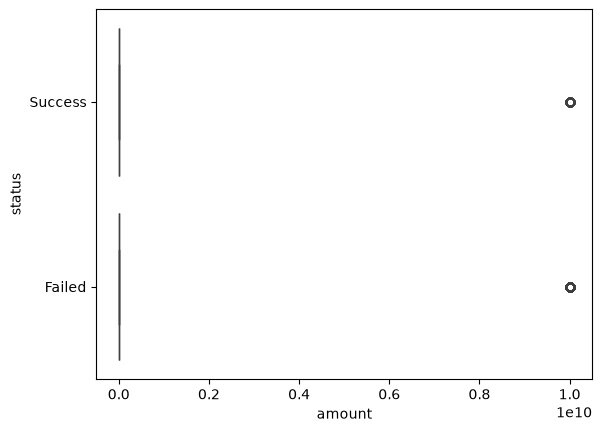

In [25]:
sns.boxplot(x='amount',data=df, y='status')

<Axes: xlabel='amount', ylabel='Count'>

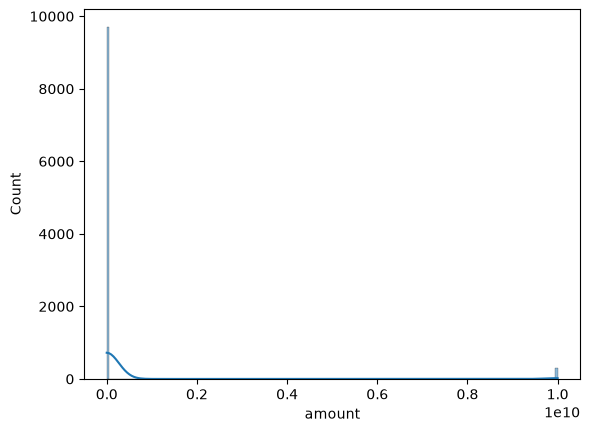

In [30]:
sns.histplot(x='amount',data=df,kde=True)

{'whiskers': [<matplotlib.lines.Line2D at 0x11a56b380>,
 'caps': [<matplotlib.lines.Line2D at 0x11a56b620>,
 'boxes': [<matplotlib.lines.Line2D at 0x11a56b230>],
 'medians': [<matplotlib.lines.Line2D at 0x11a56b8c0>],
 'fliers': [<matplotlib.lines.Line2D at 0x11a56ba10>],
 'means': []}

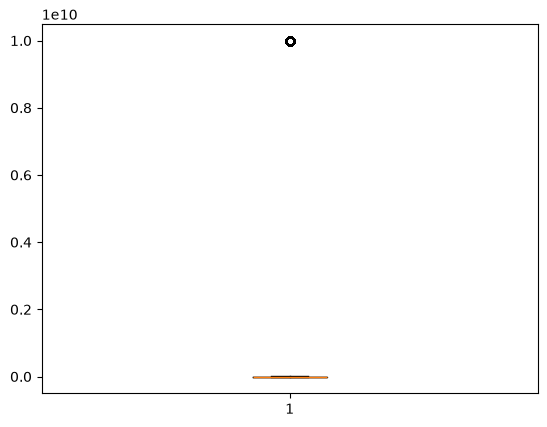

In [39]:
plt.boxplot(df['amount'])

In [43]:
df[df['amount']==0]

,status,time,card_type,city,amount,id,temp
3,Success,2025-09-15 13:13:00,Discover,Isfahan,0.0,40,True
9,Failed,2025-09-26 07:32:00,Visa,Tehran,0.0,82,True
28,Success,2025-09-28 03:27:00,MastCard,Shiraz,0.0,69,True
60,Failed,2025-09-07 09:09:00,Discover,Unknown,0.0,73,True
63,Failed,2025-09-25 19:29:00,MasterCard,Tehran,0.0,96,True
...,...,...,...,...,...,...,...
9931,Success,2025-09-13 01:51:00,MasterCard,karaj,0.0,29,True
9935,Success,2025-09-10 02:30:00,Discover,Tehran,0.0,80,True
9941,Success,2025-09-21 16:16:00,Vsa,Karaj,0.0,78,True
9951,Success,2025-09-17 08:59:00,Master Card,Tehran,0.0,83,True
